# Load Dữ liệu

In [1]:
import pandas as pd
data = pd.read_csv('smsspamcollection/SMSSpamCollection.txt', sep ='\t',
                header= None, 
                names = ['label', 'message'])

In [2]:
data.shape

(5572, 2)

# Tiền xử lí dữ liệu

In [3]:
cleaned_data = data.drop_duplicates().reset_index(drop=True)

In [4]:
cleaned_data

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5164,spam,This is the 2nd time we have tried 2 contact u...
5165,ham,Will ü b going to esplanade fr home?
5166,ham,"Pity, * was in mood for that. So...any other s..."
5167,ham,The guy did some bitching but I acted like i'd...


# So sánh hai kiểu vector hóa dạng text

# Vector hóa theo dạng đếm số lần xuất hiện của các từ

In [5]:
from sklearn.feature_extraction.text import CountVectorizer

In [6]:
vectorizer = CountVectorizer()

In [7]:
vectorizer

,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None
,stop_words,None
,token_pattern,'(?u)\\b\\w\\w+\\b'
,ngram_range,"(1, ...)"
,analyzer,'word'


# trích xuất dữ liệu mỗi cột tương ứng với số lần xuất hiện trong một cái message

In [8]:
X = vectorizer.fit_transform(cleaned_data["message"])

In [9]:
selected_words = X.toarray()

In [10]:
vectorizer.vocabulary_.get("you")

8668

In [11]:
selected_word_table = pd.DataFrame(selected_words, columns=vectorizer.get_feature_names_out())

In [12]:
selected_word_table

,00,000,000pes,008704050406,0089,0121,01223585236,01223585334,0125698789,02,...,zhong,zindgi,zoe,zogtorius,zoom,zouk,zyada,èn,ú1,〨ud
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5164,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5165,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5166,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5167,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [13]:
final_data = pd.concat([cleaned_data["label"], selected_word_table], axis=1)

In [14]:
final_data.shape

(5169, 8714)

In [15]:
final_data.shape

(5169, 8714)

In [16]:
result = final_data.drop(columns="message")

# Chia dữ liệu ra cho mô hình huấn luyện

In [17]:
y = result["label"]

In [18]:
X = result.drop(columns = "label")

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

In [21]:
from sklearn.naive_bayes import MultinomialNB

In [22]:
clf_1 = MultinomialNB()


In [23]:
clf_1.fit(X_train, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [24]:
pred = clf_1.predict(X_test)

In [25]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [26]:
accuracy_score(y_test, pred)

0.9761444229529336

In [27]:
confusion_matrix(y_test, pred)

array([[1329,   18],
       [  19,  185]])

In [28]:
from sklearn.svm import LinearSVC

clf_2 = LinearSVC(
    C=1.0,                  
    class_weight='balanced', 
    max_iter=10000,          
    random_state=42
)

In [29]:
clf_2.fit(X_train, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,verbose,0
,random_state,42


In [30]:
pred_2 = clf_2.predict(X_test)

In [31]:
accuracy_score(y_test, pred_2)

0.9845261121856866

In [32]:
confusion_matrix(y_test, pred_2)

array([[1345,    2],
       [  22,  182]])

In [33]:
print(classification_report(y_test, pred_2))

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99      1347
        spam       0.99      0.89      0.94       204

    accuracy                           0.98      1551
   macro avg       0.99      0.95      0.96      1551
weighted avg       0.98      0.98      0.98      1551



# Thử trên nhiều mô hình để so sánh nhiều model lại với nhau

In [34]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Dùng chung X_train, X_test, y_train, y_test đã split từ TF-IDF

models = {
    "MultinomialNB": MultinomialNB(),
    "LinearSVC (no weight)": LinearSVC(max_iter=10000, random_state=42),
    "LinearSVC (balanced)": LinearSVC(class_weight='balanced', max_iter=10000, random_state=42),
    "LogisticRegression (balanced)": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    print(f"===== {name} =====")
    print(f"Accuracy: {accuracy_score(y_test, pred):.4f}")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))
    print()

===== MultinomialNB =====
Accuracy: 0.9761
Confusion matrix:
[[1329   18]
 [  19  185]]
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99      1347
        spam       0.91      0.91      0.91       204

    accuracy                           0.98      1551
   macro avg       0.95      0.95      0.95      1551
weighted avg       0.98      0.98      0.98      1551


===== LinearSVC (no weight) =====
Accuracy: 0.9845
Confusion matrix:
[[1345    2]
 [  22  182]]
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99      1347
        spam       0.99      0.89      0.94       204

    accuracy                           0.98      1551
   macro avg       0.99      0.95      0.96      1551
weighted avg       0.98      0.98      0.98      1551


===== LinearSVC (balanced) =====
Accuracy: 0.9845
Confusion matrix:
[[1345    2]
 [  22  182]]
              precision    recall  f1-score   support

         h

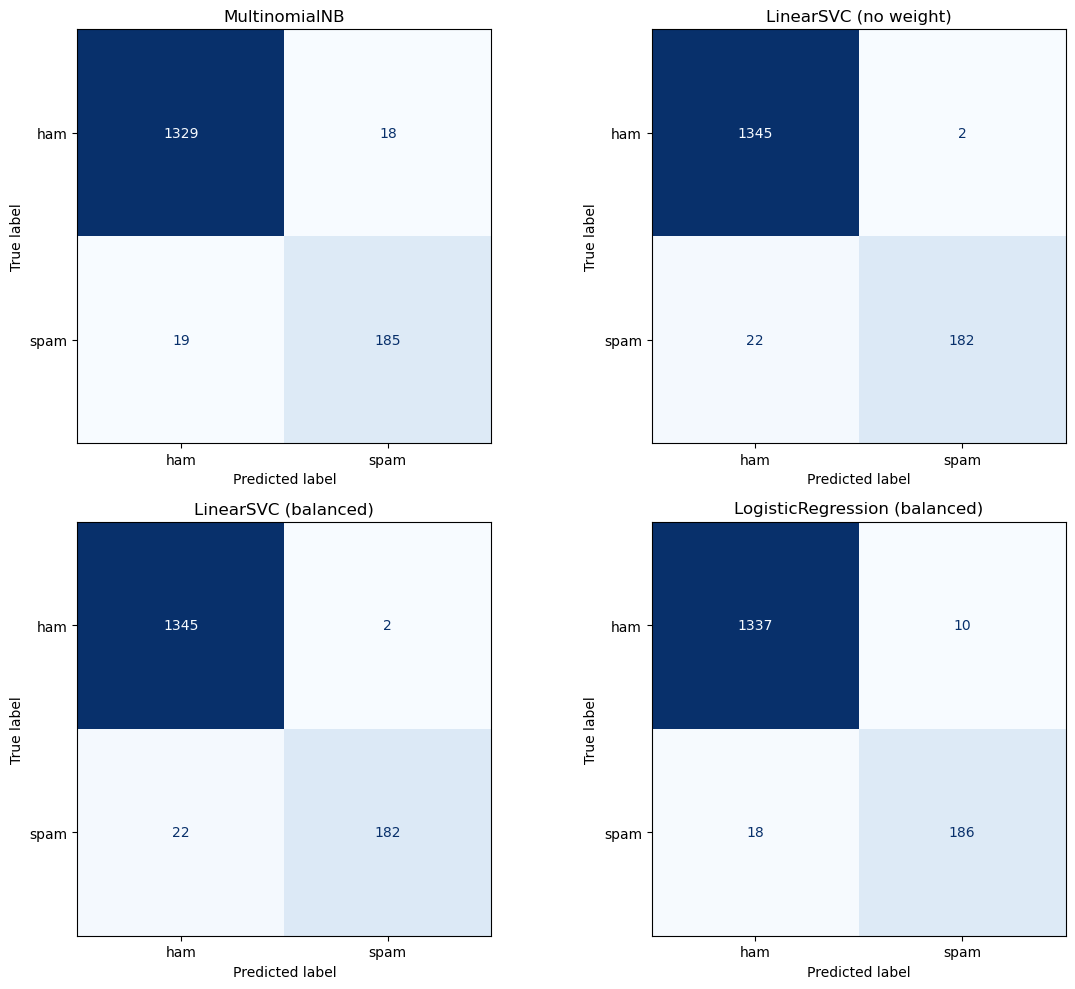

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
weight_vectorizer = TfidfVectorizer()

In [37]:
weight_vectorizer

,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None
,analyzer,'word'
,stop_words,None
,token_pattern,'(?u)\\b\\w\\w+\\b'
,ngram_range,"(1, ...)"


In [38]:
X = weight_vectorizer.fit_transform(cleaned_data["message"])

In [39]:
selected_words = X.toarray()

In [40]:
weight_vectorizer.vocabulary_.get("you")

8668

In [41]:
selected_word_table = pd.DataFrame(selected_words, columns=weight_vectorizer.get_feature_names_out())

In [42]:
selected_word_table

,00,000,000pes,008704050406,0089,0121,01223585236,01223585334,0125698789,02,...,zhong,zindgi,zoe,zogtorius,zoom,zouk,zyada,èn,ú1,〨ud
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5164,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5165,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5166,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5167,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [43]:
final_data = pd.concat([cleaned_data["label"], selected_word_table], axis=1)

In [44]:
final_data.shape

(5169, 8714)

In [45]:
final_data.shape

(5169, 8714)

In [46]:
result = final_data.drop(columns="message")

In [47]:
y = result["label"]

In [48]:
X = result.drop(columns = "label")

In [49]:
from sklearn.model_selection import train_test_split

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

In [51]:
from sklearn.naive_bayes import MultinomialNB

In [52]:
clf_1 = MultinomialNB()


In [53]:
clf_1.fit(X_train, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [54]:
pred = clf_1.predict(X_test)

In [55]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [56]:
accuracy_score(y_test, pred)

0.9445519019987105

In [57]:
confusion_matrix(y_test, pred)

array([[1348,    0],
       [  86,  117]])

In [58]:
from sklearn.svm import LinearSVC

clf_2 = LinearSVC(
    C=1.0,                  
    class_weight='balanced', 
    max_iter=10000,          
    random_state=42
)

In [59]:
clf_2.fit(X_train, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,verbose,0
,random_state,42


In [60]:
pred_2 = clf_2.predict(X_test)

In [61]:
accuracy_score(y_test, pred_2)

0.9780786589297228

In [62]:
confusion_matrix(y_test, pred)

array([[1348,    0],
       [  86,  117]])

In [63]:
print(classification_report(y_test, pred_2))

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99      1348
        spam       0.97      0.86      0.91       203

    accuracy                           0.98      1551
   macro avg       0.98      0.93      0.95      1551
weighted avg       0.98      0.98      0.98      1551



In [64]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Dùng chung X_train, X_test, y_train, y_test đã split từ TF-IDF

models = {
    "MultinomialNB": MultinomialNB(),
    "LinearSVC (no weight)": LinearSVC(max_iter=10000, random_state=42),
    "LinearSVC (balanced)": LinearSVC(class_weight='balanced', max_iter=10000, random_state=42),
    "LogisticRegression (balanced)": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    print(f"===== {name} =====")
    print(f"Accuracy: {accuracy_score(y_test, pred):.4f}")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))
    print()

===== MultinomialNB =====
Accuracy: 0.9446
Confusion matrix:
[[1348    0]
 [  86  117]]
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97      1348
        spam       1.00      0.58      0.73       203

    accuracy                           0.94      1551
   macro avg       0.97      0.79      0.85      1551
weighted avg       0.95      0.94      0.94      1551


===== LinearSVC (no weight) =====
Accuracy: 0.9755
Confusion matrix:
[[1344    4]
 [  34  169]]
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99      1348
        spam       0.98      0.83      0.90       203

    accuracy                           0.98      1551
   macro avg       0.98      0.91      0.94      1551
weighted avg       0.98      0.98      0.97      1551


===== LinearSVC (balanced) =====
Accuracy: 0.9781
Confusion matrix:
[[1343    5]
 [  29  174]]
              precision    recall  f1-score   support

         h

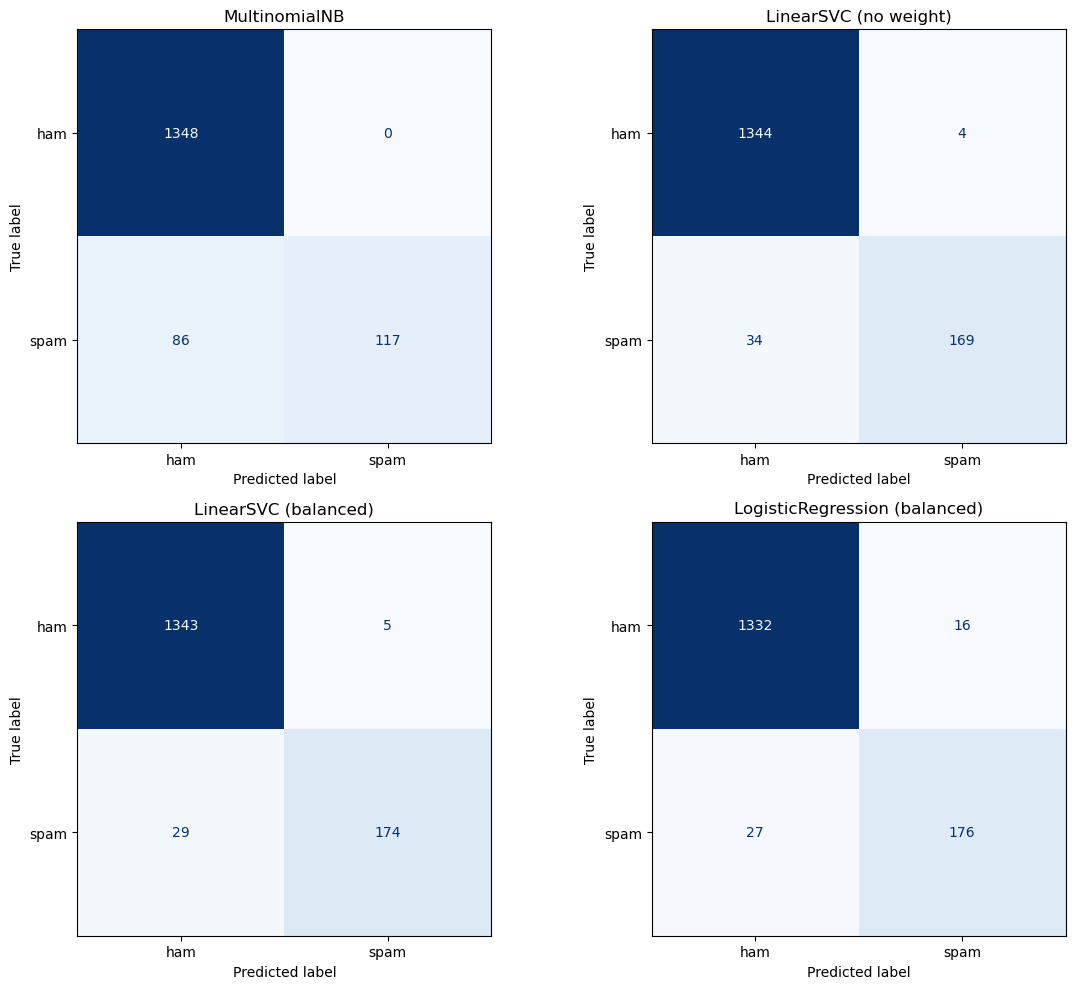

In [65]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

# So sánh kết quả hai phương pháp khác nhau
## 1. Đếm dựa trên số lượng xuất hiện của từ tương ứng với mỗi cột feature `CountVectorizer`
|Model|Precision|Recall|
|---|---|---|
|MultinomialNB|91.1%|90.7%|
|LinearSVC (no weight)|98.9%|89.2%|
|LinearSVC (balanced)|98.9%|89.2%|
|LogisticRegression (balanced)|94.9%|91.2%|
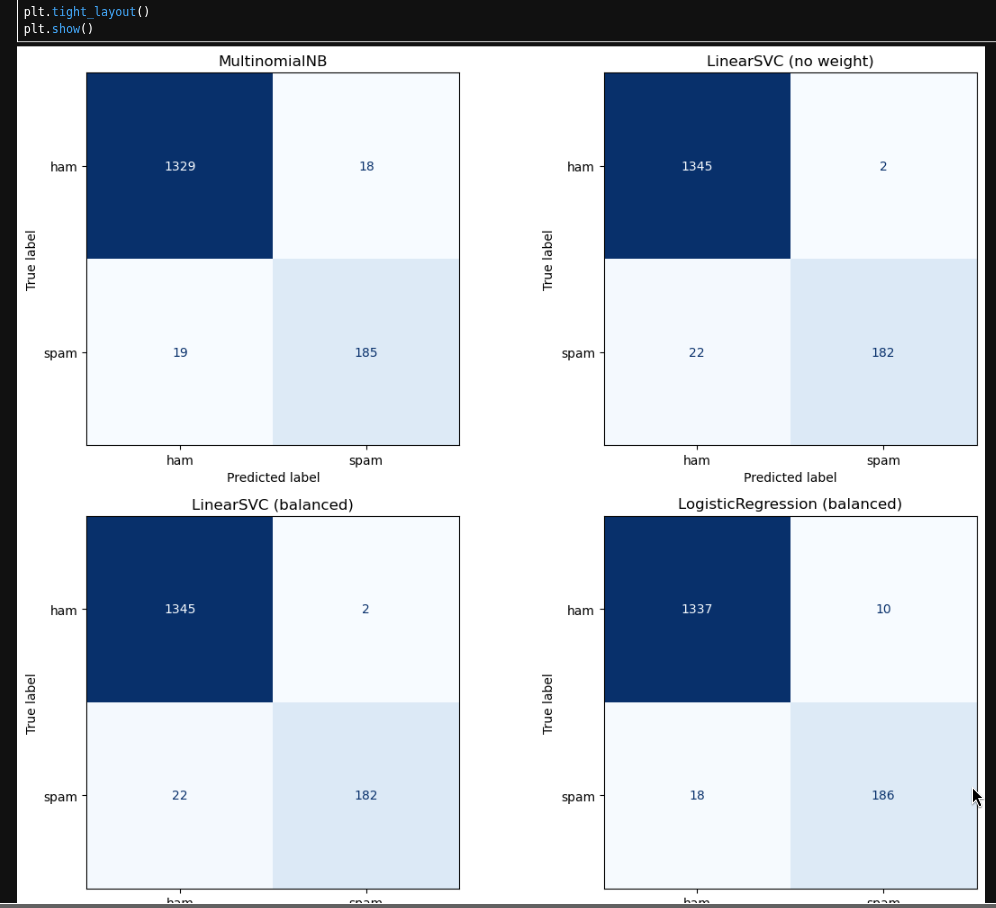
## 2. Gắn trọng số cho từng feature dựa trên số lần xuất hiện của từ `TfidfTransformer`
|Model|Precision|Recall|
|---|---|---|
|MultinomialNB|57.7%|57.6%|
|LinearSVC (no weight)|97.7%|83.3%|
|LinearSVC (balanced)|97.2%	|85.7%|
|LogisticRegression (balanced)|91.7%|86.7%|
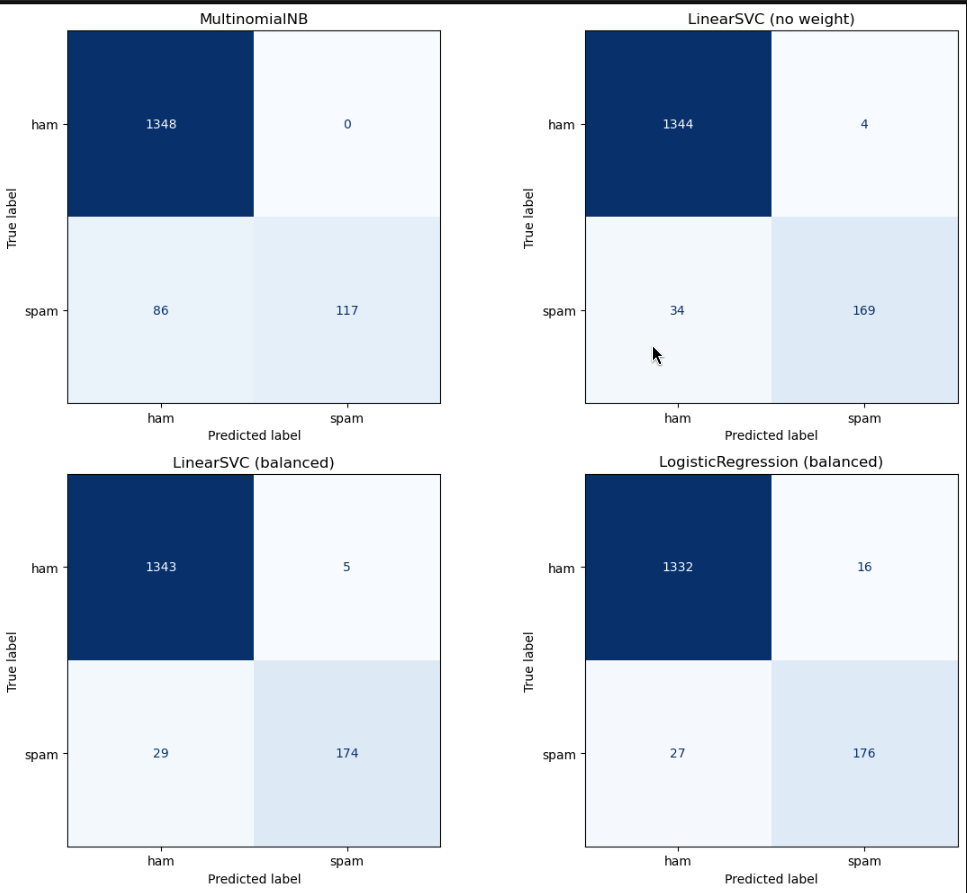

Nhận xét:
> so với việc không có trọng số so với cách `CountVectorizer` thì hiệu quả hơn so với cách `TfidfTransformer`
- Do chỉ số recall cao hơn
- Vì email dựa vào chỉ số `recall` để đánh giá số email spam phải được phát hiện nhiều hơn so với email `ham`
- Có thể thấy chỉ số trung bình của recall của cách `1` nó cao hơn ở nhiều model hơn so với cách `2` 